# 基于颜色直方图与预训练深度特征的“以图搜图”实验

本 Notebook 对应课程作业要求，完整实现并验证基于内容的图像检索（CBIR）流程：
1. **数据集构建与划分**：包含 10 个语义类别，每类选取 2 张图片组成查询集（共 20 张），其余 9,469 张图片组成检索库。
2. **图像读取与预处理**：统一进行 EXIF 方向校正与 RGB 三通道转换；针对深度特征执行与 ImageNet 预训练一致的缩放、中心裁剪与均值方差归一化。
3. **特征提取**：分别实现 **RGB 颜色直方图特征（48 维）** 与 **预训练 ResNet-50 深度特征（2048 维）**。
4. **相似度计算与排序**：对 $L_2$ 归一化特征计算余弦相似度（并对比欧氏距离、$L_1$ 距离与直方图相交度），返回 Top-5 检索结果。
5. **检索结果可视化与定量分析**：展示全部查询图的 Top-5 检索结果，并统计 Top-1 准确率、Hit@5、Precision@5 与 mAP@5。

## 1. 数据集构建与类别分布统计

类别总数：10 类（作业要求 ≥ 5 类）
查询集图片总数：20 张（每类 2 张）
检索库图片总数：9469 张（作业要求 ≥ 40 张）

类别名称                      查询集数量        检索库数量
----------------------------------------------
English springer              2          955
French horn                   2          956
cassette player               2          993
chain saw                     2          858
church                        2          941
garbage truck                 2          961
gas pump                      2          931
golf ball                     2          951
parachute                     2          960
tench                         2          963
<IPython.core.display.Image object>


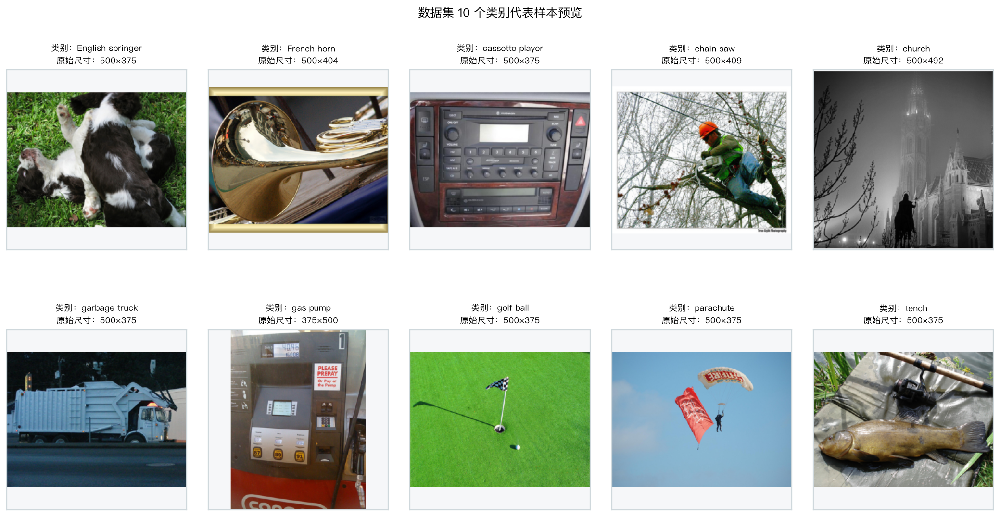

In [1]:
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
from IPython.display import Image as DisplayImage, display

from cbir import (
    DeepFeatureExtractor,
    FeatureGallery,
    HistogramFeatureExtractor,
    evaluate_retrieval,
    list_image_paths,
    load_rgb_image,
    plot_dataset_samples,
    plot_evaluation_comparison,
    plot_feature_illustration,
    plot_method_comparison,
    plot_search_results,
    select_query_paths,
)

DATASET_ROOT = Path("dataset")
GALLERY_ROOT = DATASET_ROOT / "gallery"
QUERY_ROOT = DATASET_ROOT / "query"
RESULT_ROOT = Path("results/notebook")
RESULT_ROOT.mkdir(parents=True, exist_ok=True)

# 每类选 2 张查询图，检索库使用 gallery 中的全部图片
gallery_paths = list_image_paths(GALLERY_ROOT)
query_paths = select_query_paths(QUERY_ROOT, per_category=2)

if not gallery_paths or not query_paths:
    raise FileNotFoundError("请确认 dataset/query 和 dataset/gallery 中存在按类别组织的图片。")

categories = sorted({path.parent.name for path in gallery_paths})
assert len(categories) >= 5, "类别数量应不少于 5 类"

gallery_counts = Counter(path.parent.name for path in gallery_paths)
query_counts = Counter(path.parent.name for path in query_paths)

print(f"类别总数：{len(categories)} 类（作业要求 ≥ 5 类）")
print(f"查询集图片总数：{len(query_paths)} 张（每类 {len(query_paths)//len(categories)} 张）")
print(f"检索库图片总数：{len(gallery_paths)} 张（作业要求 ≥ 40 张）\n")
print(f"{'类别名称':<20} {'查询集数量':>10} {'检索库数量':>12}")
print("-" * 46)
for cat in categories:
    print(f"{cat:<20} {query_counts[cat]:>10d} {gallery_counts[cat]:>12d}")

# 每个类别取第 1 张查询图展示数据集代表样本
sample_paths = query_paths[::2]
sample_fig_path = RESULT_ROOT / "dataset_samples.png"
fig = plot_dataset_samples(sample_paths, cols=5, save_path=sample_fig_path, show=False)
plt.close(fig)
display(DisplayImage(filename=str(sample_fig_path)))
_record_image(sample_fig_path)

## 2. 图像读取、预处理与特征提取验证

- **RGB 颜色直方图预处理与提取**：读取图像并转换为标准 RGB 三通道格式，在 `[0, 256)` 范围内按每个通道 16 个区间（bin）统计像素频数，除以总像素数完成单通道概率归一化（消除不同图片尺寸的影响），拼接得到 48 维特征向量后再做 $L_2$ 归一化。
- **ResNet-50 深度特征预处理与提取**：采用 `ResNet50_Weights.IMAGENET1K_V2` 对应的标准变换（先双线性插值缩放至短边 232，中心裁剪至 $224\times 224$，再按 ImageNet 均值 `(0.485, 0.456, 0.406)` 与标准差 `(0.229, 0.224, 0.225)` 归一化），提取全局平均池化层输出的 2048 维特征向量并做 $L_2$ 归一化。

示例图片路径：dataset/query/English springer/ILSVRC2012_val_00004650.JPEG (原始尺寸: 500×375)
RGB 单通道直方图形状：(3, 16)，各通道概率和：[1. 1. 1.]
拼接并 L2 归一化后颜色特征维度：(48,)，L2 范数：1.0000
ResNet-50 预处理流程：ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
ResNet-50 深度特征维度：(2048,)，L2 范数：1.0000
<IPython.core.display.Image object>


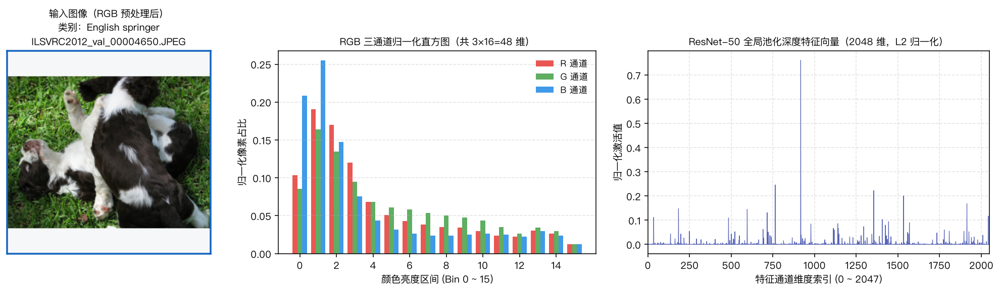

In [2]:
histogram_extractor = HistogramFeatureExtractor(bins_per_channel=16)
deep_extractor = DeepFeatureExtractor()

demo_query = query_paths[0]
raw_rgb = load_rgb_image(demo_query)
channel_hists = histogram_extractor.extract_channel_histograms(demo_query)
hist_feature = histogram_extractor.extract(demo_query)
deep_feature = deep_extractor.extract(demo_query)

print(f"示例图片路径：{demo_query} (原始尺寸: {raw_rgb.size[0]}×{raw_rgb.size[1]})")
print(f"RGB 单通道直方图形状：{channel_hists.shape}，各通道概率和：{channel_hists.sum(axis=1).round(4)}")
print(f"拼接并 L2 归一化后颜色特征维度：{hist_feature.vector.shape}，L2 范数：{float((hist_feature.vector**2).sum()**0.5):.4f}")
print(f"ResNet-50 预处理流程：{deep_extractor.preprocess}")
print(f"ResNet-50 深度特征维度：{deep_feature.vector.shape}，L2 范数：{float((deep_feature.vector**2).sum()**0.5):.4f}")

feat_fig_path = RESULT_ROOT / "feature_illustration.png"
fig = plot_feature_illustration(
    demo_query,
    histogram_extractor,
    deep_feature.vector,
    save_path=feat_fig_path,
    show=False,
)
plt.close(fig)
display(DisplayImage(filename=str(feat_fig_path)))
_record_image(feat_fig_path)

## 3. 基于 RGB 颜色直方图的以图搜图与 Top-5 可视化

<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
RGB 颜色直方图检索完成（共 20 张查询图）｜Top-1 准确率: 45.0% | Precision@5: 35.0% | mAP@5: 49.6%


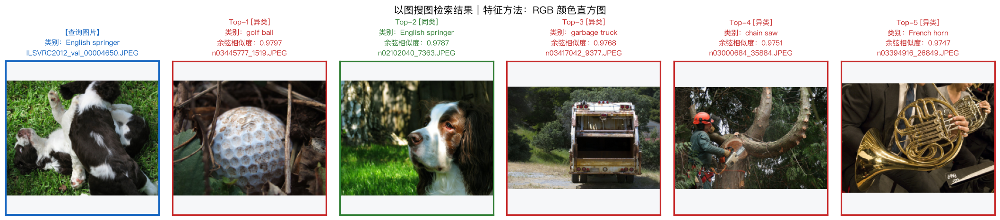

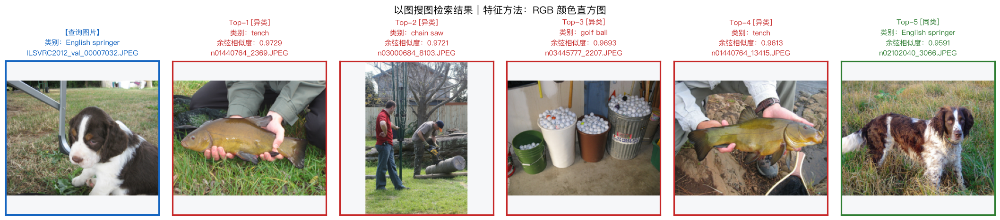

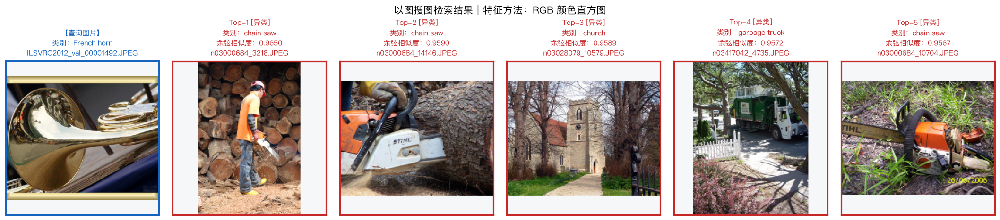

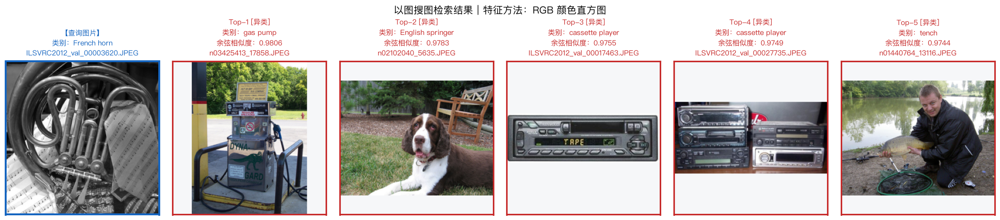

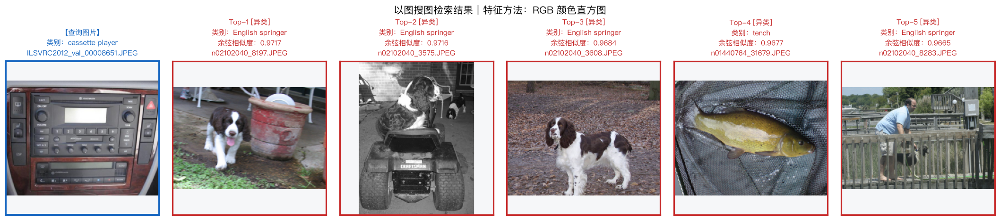

...

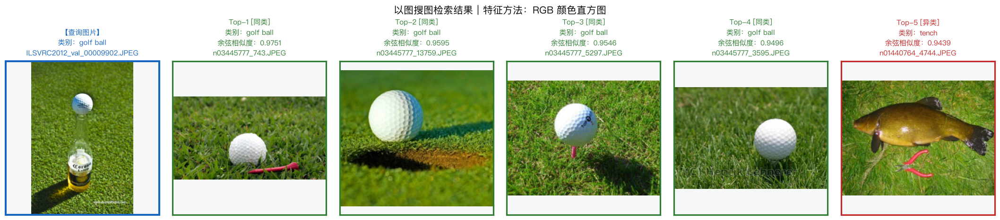

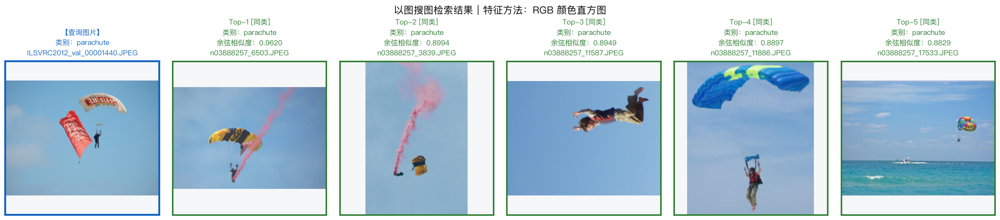

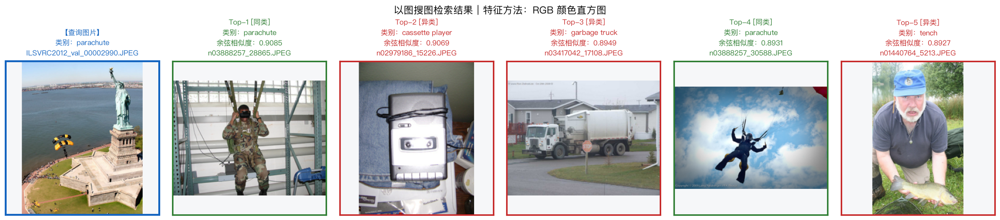

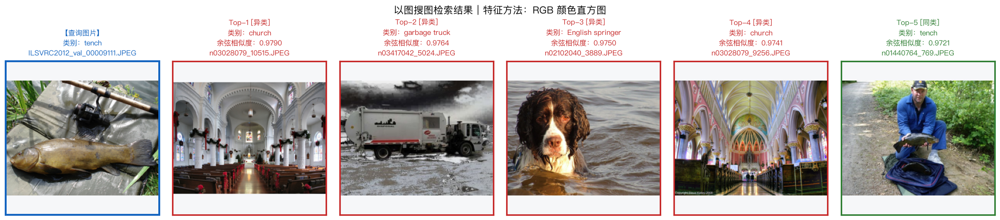

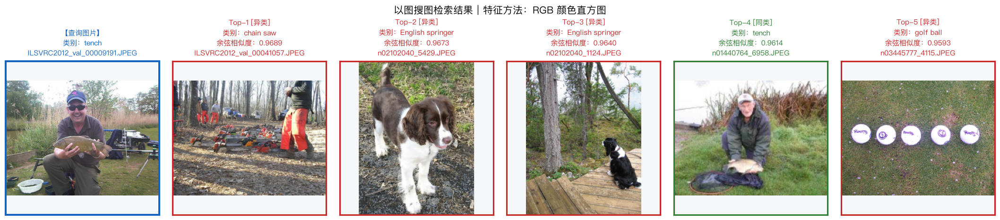

In [3]:
histogram_gallery = FeatureGallery.build_or_load(
    gallery_paths,
    histogram_extractor,
    cache_path=Path("cache/notebook_histogram_gallery.npz"),
    categories=[path.parent.name for path in gallery_paths],
)

histogram_eval = evaluate_retrieval(
    gallery=histogram_gallery,
    query_paths=query_paths,
    extractor=histogram_extractor,
    method_name="RGB 颜色直方图",
    top_k=5,
    metric="cosine",
)

histogram_results = []
for index, q_eval in enumerate(histogram_eval.queries, start=1):
    query_path = q_eval.query_path
    results = q_eval.results
    save_path = RESULT_ROOT / "histogram" / f"{index:02d}_{query_path.parent.name}.png"
    figure = plot_search_results(
        query_path=query_path,
        results=results,
        feature_method="RGB 颜色直方图",
        query_category=q_eval.query_category,
        save_path=save_path,
        show=False,
    )
    plt.close(figure)
    display(DisplayImage(filename=str(save_path)))
    _record_image(save_path)
    histogram_results.append((query_path, results, save_path))

print(
    f"RGB 颜色直方图检索完成（共 {len(histogram_results)} 张查询图）｜"
    f"Top-1 准确率: {histogram_eval.top1_accuracy:.1%} | "
    f"Precision@5: {histogram_eval.mean_precision_at_k:.1%} | "
    f"mAP@5: {histogram_eval.map_at_k:.1%}"
)

## 4. 基于预训练 ResNet-50 深度特征的以图搜图与 Top-5 可视化

<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
ResNet-50 深度特征检索完成（共 20 张查询图）｜Top-1 准确率: 100.0% | Precision@5: 100.0% | mAP@5: 100.0%


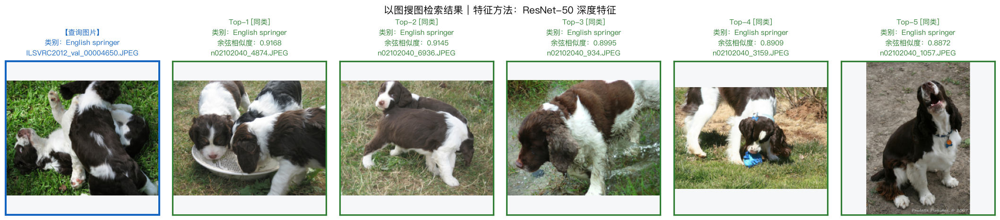

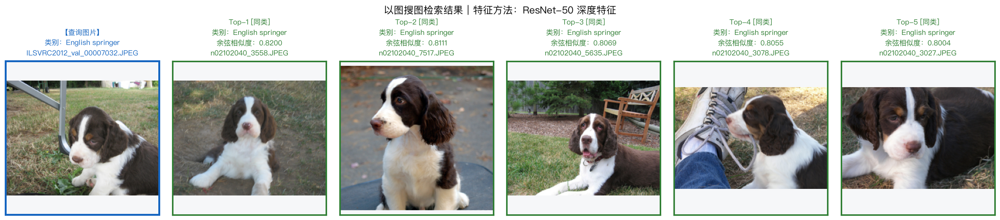

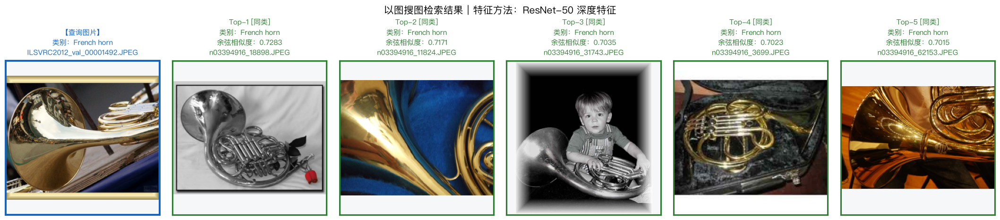

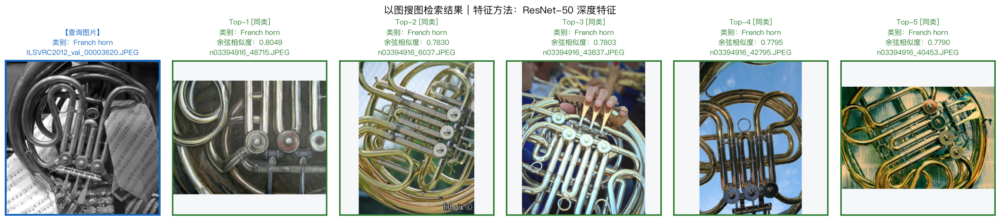

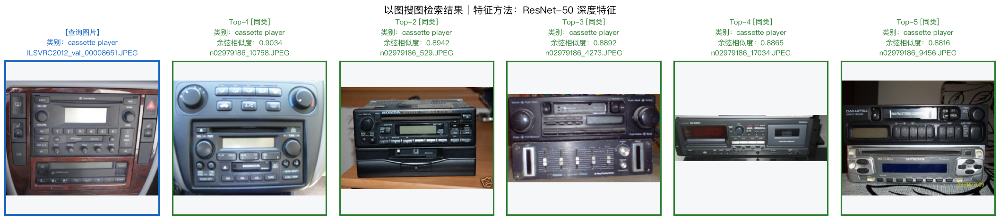

...

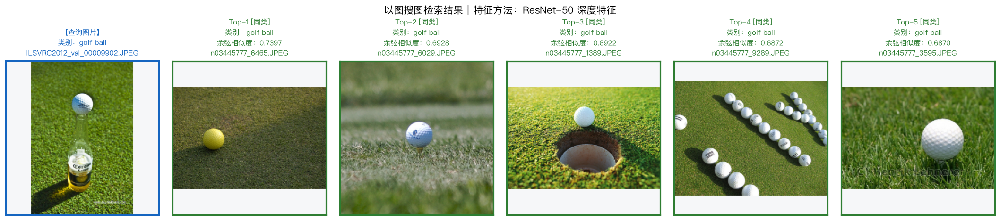

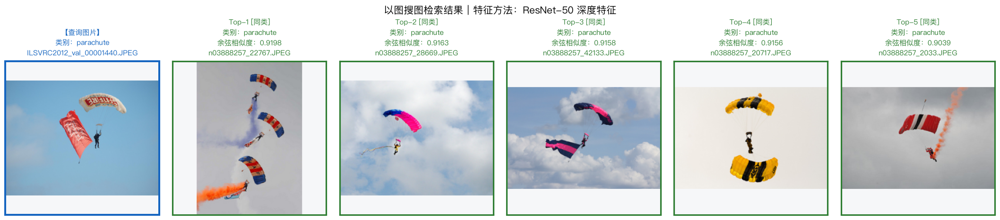

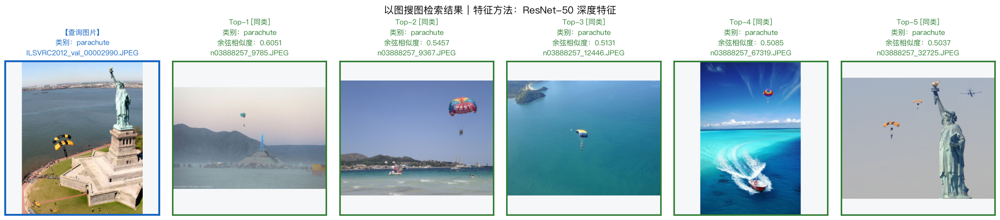

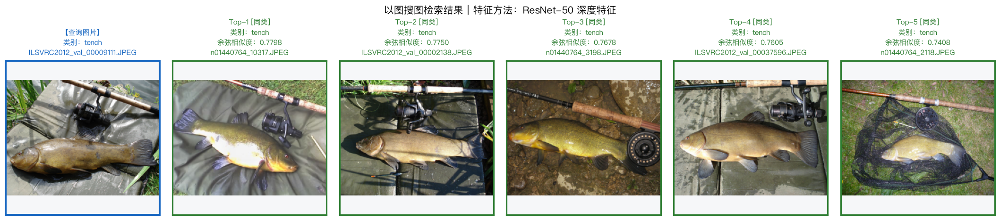

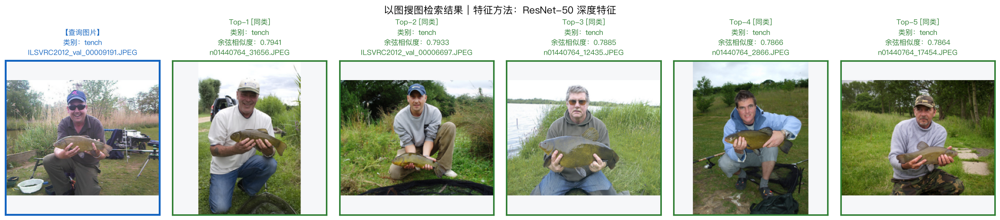

In [4]:
deep_gallery = FeatureGallery.build_or_load(
    gallery_paths,
    deep_extractor,
    cache_path=Path("cache/notebook_deep_gallery.npz"),
    categories=[path.parent.name for path in gallery_paths],
)

deep_eval = evaluate_retrieval(
    gallery=deep_gallery,
    query_paths=query_paths,
    extractor=deep_extractor,
    method_name="ResNet-50 深度特征",
    top_k=5,
    metric="cosine",
)

deep_results = []
for index, q_eval in enumerate(deep_eval.queries, start=1):
    query_path = q_eval.query_path
    results = q_eval.results
    save_path = RESULT_ROOT / "deep" / f"{index:02d}_{query_path.parent.name}.png"
    figure = plot_search_results(
        query_path=query_path,
        results=results,
        feature_method="ResNet-50 深度特征",
        query_category=q_eval.query_category,
        save_path=save_path,
        show=False,
    )
    plt.close(figure)
    display(DisplayImage(filename=str(save_path)))
    _record_image(save_path)
    deep_results.append((query_path, results, save_path))

print(
    f"ResNet-50 深度特征检索完成（共 {len(deep_results)} 张查询图）｜"
    f"Top-1 准确率: {deep_eval.top1_accuracy:.1%} | "
    f"Precision@5: {deep_eval.mean_precision_at_k:.1%} | "
    f"mAP@5: {deep_eval.map_at_k:.1%}"
)

## 5. 两种特征方法的定量对比与典型案例剖析

=== 1. 整体检索指标对比（20 张查询图，检索库 9,469 张）===
特征方法                  Top-1 准确率      Hit@5    Precision@5      mAP@5
----------------------------------------------------------------------
RGB 颜色直方图                 45.0%      85.0%          35.0%      49.6%
ResNet-50 深度特征           100.0%     100.0%         100.0%     100.0%

=== 2. 颜色直方图在不同距离/相似度度量下的对比 ===
度量方式 cosine        : Top-1 = 45.0%, Precision@5 = 35.0%, mAP@5 = 49.6%
度量方式 euclidean     : Top-1 = 45.0%, Precision@5 = 35.0%, mAP@5 = 49.6%
度量方式 l1            : Top-1 = 45.0%, Precision@5 = 34.0%, mAP@5 = 50.3%
度量方式 intersection  : Top-1 = 40.0%, Precision@5 = 32.0%, mAP@5 = 50.2%
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>
<IPython.core.display.Image object>


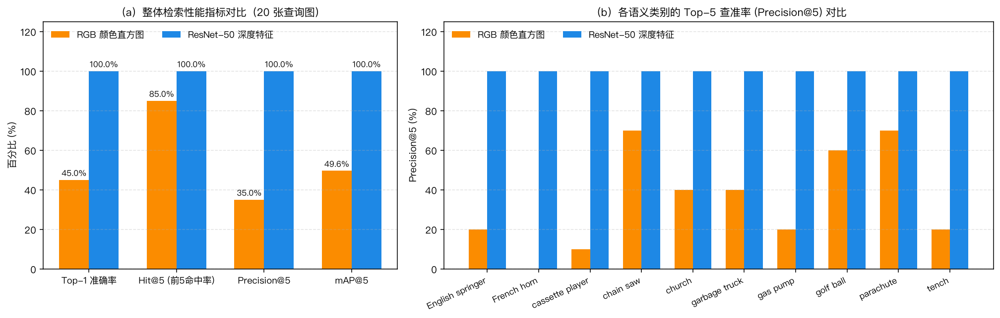

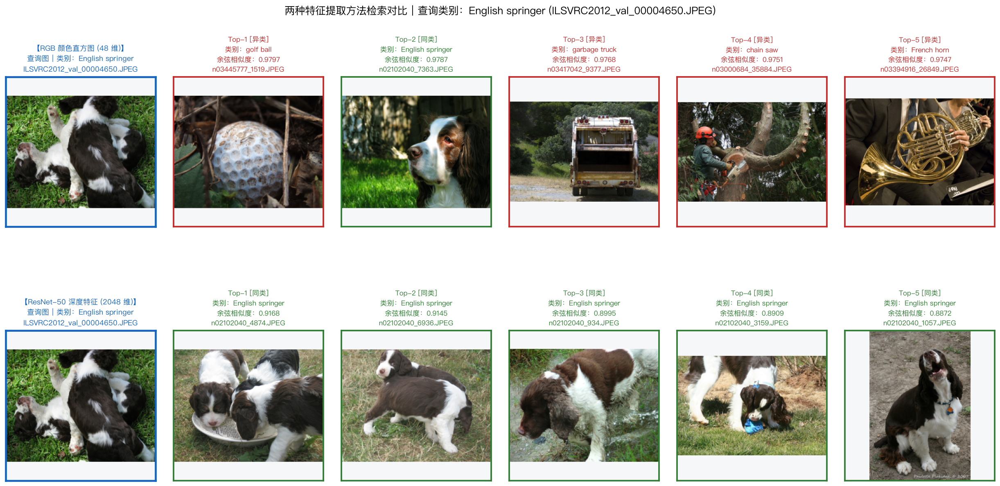

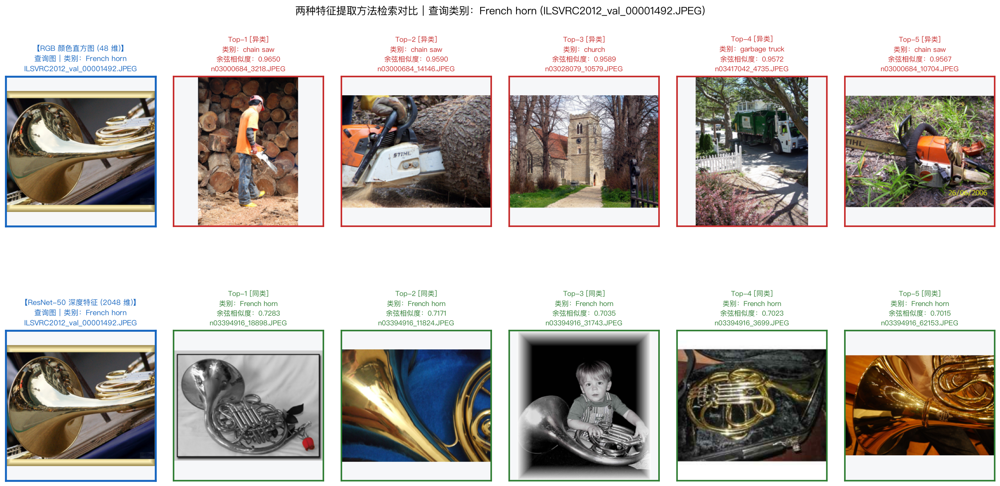

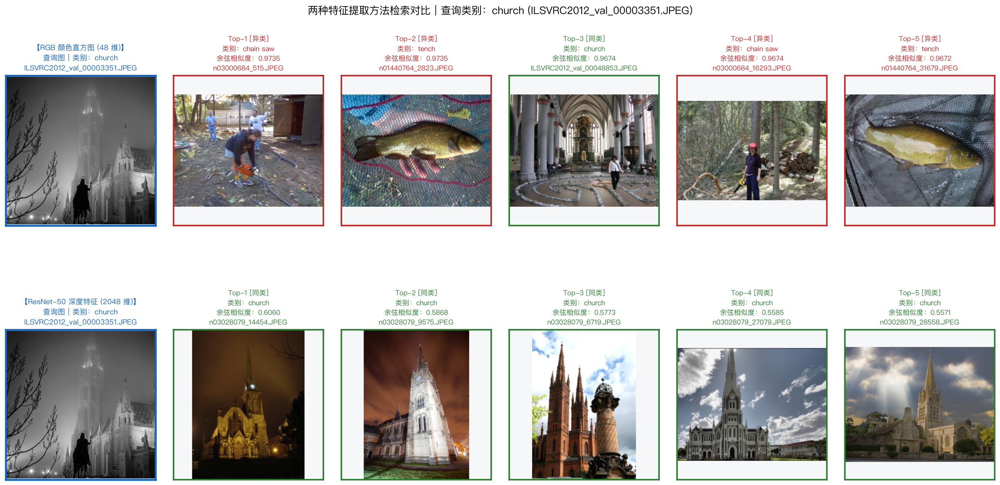

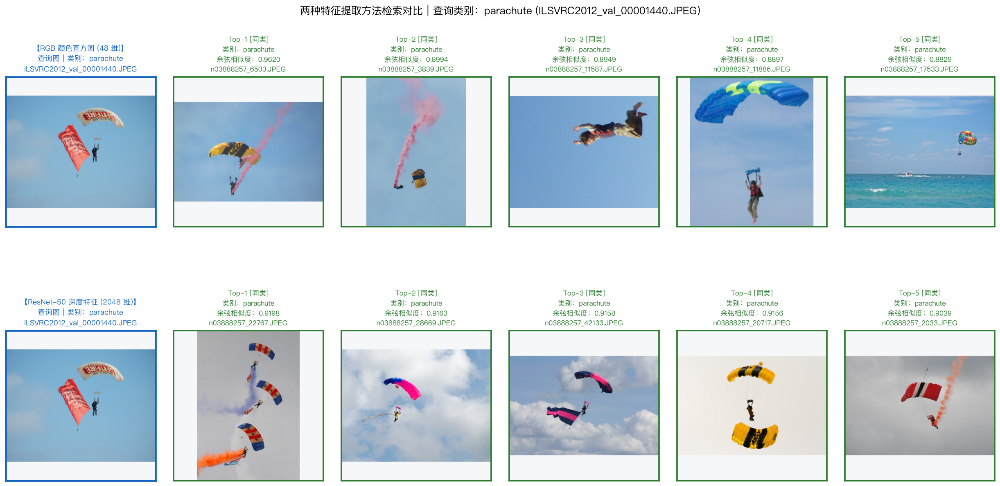

In [5]:
print("=== 1. 整体检索指标对比（20 张查询图，检索库 9,469 张）===")
print(f"{'特征方法':<18} {'Top-1 准确率':>12} {'Hit@5':>10} {'Precision@5':>14} {'mAP@5':>10}")
print("-" * 70)
for ev in (histogram_eval, deep_eval):
    print(
        f"{ev.method_name:<18} {ev.top1_accuracy:>12.1%} "
        f"{ev.hit_rate_at_k:>10.1%} {ev.mean_precision_at_k:>14.1%} {ev.map_at_k:>10.1%}"
    )

print("\n=== 2. 颜色直方图在不同距离/相似度度量下的对比 ===")
for metric_name in ("cosine", "euclidean", "l1", "intersection"):
    m_eval = evaluate_retrieval(
        histogram_gallery, query_paths, histogram_extractor,
        method_name=f"Hist ({metric_name})", top_k=5, metric=metric_name,
    )
    print(
        f"度量方式 {metric_name:<14}: Top-1 = {m_eval.top1_accuracy:>5.1%}, "
        f"Precision@5 = {m_eval.mean_precision_at_k:>5.1%}, mAP@5 = {m_eval.map_at_k:>5.1%}"
    )

eval_fig_path = RESULT_ROOT / "evaluation_comparison.png"
fig = plot_evaluation_comparison(histogram_eval, deep_eval, save_path=eval_fig_path, show=False)
plt.close(fig)
display(DisplayImage(filename=str(eval_fig_path)))
_record_image(eval_fig_path)

# 选取 4 个典型案例进行上下同图对比（01: English springer, 03: French horn, 09: church, 17: parachute）
for case_idx in (0, 2, 8, 16):
    q_path = query_paths[case_idx]
    h_res = histogram_eval.queries[case_idx].results
    d_res = deep_eval.queries[case_idx].results
    cmp_path = RESULT_ROOT / f"compare_{case_idx+1:02d}_{q_path.parent.name.replace(' ', '_')}.png"
    fig = plot_method_comparison(
        query_path=q_path,
        hist_results=h_res,
        deep_results=d_res,
        query_category=q_path.parent.name,
        save_path=cmp_path,
        show=False,
    )
    plt.close(fig)
    display(DisplayImage(filename=str(cmp_path)))
    _record_image(cmp_path)

## 6. 分析与讨论要点

1. **两种特征分别描述了哪些信息？哪些信息可能被忽略？**
   - **RGB 颜色直方图**：描述整幅图像的**全局色彩统计分布**（各通道在不同亮度区间的像素占比），具备平移与旋转不变性；但它将所有像素打散统计，**完全丢失了空间位置、边缘轮廓、局部纹理以及高层语义信息**，且极易受大面积背景色（如草地、天空、暗色背景）和光照色温变化主导。例如在 `parachute`（蓝天背景）中虽有 5/5 命中，但检索出的第 3 名实际上是没有降落伞伞盖的跳伞人物（仅匹配了蓝天色调）；而在 `English springer`、`French horn`、`church` 等背景复杂或灰度相近的图像上则产生大量异类误检。
   - **ResNet-50 深度特征**：通过深层卷积神经网络提取从边缘纹理、局部部件到整体语义的**高层语义特征**，对视角变化、光照差异和背景杂波具有强鲁棒性，在 20 张查询图上实现 100% 的 Top-1 和 Precision@5；但由于网络以“类别级分类”为预训练目标且经过全局平均池化（GAP），它会**弱化精确的空间几何坐标、细粒度局部外观差异以及同类不同个体之间的身份特征**。
2. **若任务改为“找出同一件物品的不同图片”（实例级检索），需做哪些调整与评价设计？**
   - **方法调整**：① 引入目标检测或前景分割（如 YOLO / SAM）框选前景物体，剔除背景干扰；② 特征层面结合多区域池化（GeM / R-MAC）或局部关键点描述子（SuperPoint / SIFT），利用 RANSAC 单应性变换进行**空间几何一致性验证（Spatial Verification）**重排序；③ 训练目标从交叉熵分类切换为基于实例数据的**度量学习（Triplet Loss / ArcFace）**或自监督特征（如 DINOv2），并融合前景局部颜色/纹理特征以区分“同款不同色”。
   - **评价标准**：以独立物品实例 ID 标注数据集（含多视角正样本与同类别难负样本），采用兼顾召回率与排序质量的 **mAP（Mean Average Precision）**、**Recall@$K$（R@1/R@5/R@10）**、**PR 曲线**，以及开集场景下基于相似度阈值的误识率（FAR）/ 拒识率（FRR）作为核心评价指标。